# AE 696 Lab 4
## Policy Gradient, Actor Critic, and PPO on CartPole

**Due date:** See Canvas  
**Prerequisites:** Lab 3 and Lectures 15 through 18  
**Submission:** `AE696_Lab4_Lastname_Firstname.ipynb`

Implement the central calculations in REINFORCE, actor critic, and PPO. Then use your functions in three supplied training loops on `CartPole-v1`.

The policy outputs action probabilities through a categorical distribution. The critic estimates a state value. PPO reuses a recent rollout with a fixed record of the policy that collected it.

### Required work and objective grading

| Part | Student implementation or required output | Points |
|:---:|---|---:|
| A | Selected action log probabilities and entropy | 10 |
| B | Discounted rewards to go and REINFORCE loss | 20 |
| C | TD targets and actor critic losses | 20 |
| D | Generalized advantage estimation, GAE | 15 |
| E | PPO probability ratios and clipped policy loss | 20 |
| F | One gradient update with gradient clipping | 5 |
| G | Three training runs, evaluation table, and figures | 10 |
| | **Total** | **100** |

Complete only cells marked **TODO** and enter your identification. The networks, data collection, training loops, and plotting code are provided. Public checks award partial credit by named subitem. Keep function names and signatures unchanged, and do not edit the checks or required experiment settings.

Every graded item has an executable criterion. There are no essay questions and no minimum reward requirement. A low reward does not reduce the score when the implementation and required outputs pass their checks. Do not hardcode answers to the test inputs; functions must implement the stated operations for valid inputs of any batch length.

### Before submission

1. Finish Parts A through F and run their checks.
2. Run the required experiments in Part G.
3. Select **Restart Kernel and Run All**.
4. Check the final summary, then save with outputs and plots visible.
5. Submit the single notebook, with no ZIP file or separate report.

Use Python 3.10 or newer in Jupyter, VS Code, or Google Colab. A CPU is sufficient. The complete run uses about 50,000 training transitions plus evaluation. Runtime depends on the machine. Shorten runs only in a separate scratch cell; the required submission uses the supplied settings.

In [1]:
STUDENT_NAME = "Wyatt Welch"
RED_ID = "828496091"
AI_ASSISTANCE = "AI tucked me into bed and kissed me on the forehead."  # Briefly identify substantial AI assistance if used.

### Setup

If an import fails, run the following line once in a new code cell and restart the kernel:

```python
%pip install numpy matplotlib gymnasium torch
```

Training runs without opening a graphics window. The notebook prints installed versions for reproducibility. All tensors use the CPU and `float32`, except actions, which use `torch.long`, and flags, which use `torch.bool`.

In [2]:
import copy
import math
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import gymnasium as gym
import torch
from torch import nn
from torch.distributions import Categorical

SEED = 42
GAMMA = 0.99
DEVICE = torch.device("cpu")
torch.set_num_threads(1)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
print("NumPy:", np.__version__)
print("Gymnasium:", gym.__version__)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

probe_env = gym.make("CartPole-v1")
STATE_DIM = probe_env.observation_space.shape[0]
ACTION_DIM = probe_env.action_space.n
MAX_EPISODE_STEPS = probe_env.spec.max_episode_steps
probe_env.close()
print("State dimension:", STATE_DIM, "Action count:", ACTION_DIM)
print("Episode time limit:", MAX_EPISODE_STEPS)

NumPy: 2.5.4
Gymnasium: 1.4.0
PyTorch: 2.15.0+cu132
Device: cpu
State dimension: 4 Action count: 2
Episode time limit: 500


### Data and gradient conventions

A batch of states has shape `(B, 4)`, actor logits have shape `(B, 2)`, and every per-transition scalar has shape `(B,)`. Avoid mixing `(B,)` with `(B, 1)`, which can accidentally create a `(B, B)` tensor.

| Quantity | Meaning | Gradient during an update |
|---|---|---|
| `log_probs` or `new_log_probs` | Current policy log probability of the recorded action | Yes |
| `values` | Current critic prediction | Yes, for critic loss |
| `returns`, `targets`, `advantages` | Learning signals treated as fixed data | No |
| `old_log_probs` | Log probabilities saved when collecting the rollout | No |

Use `.detach()` to treat a tensor as a constant in a loss. It does not turn the entire loss into a constant. Use `torch.no_grad()` for rollout collection; the update recomputes current log probabilities and values with gradients enabled.

For actor critic and PPO, true termination removes the next-state value. A time-limit truncation ends the episode but retains the next-state value. GAE must also stop its recursion across a reset. The collector saves the final next-state value **before** resetting the environment.

In [3]:
# Provided networks. The actor and critic have separate parameters.
class ActorCritic(nn.Module):
    def __init__(self, state_dim=STATE_DIM, action_dim=ACTION_DIM, hidden_dim=64):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, action_dim),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.orthogonal_(module.weight, gain=math.sqrt(2))
                nn.init.zeros_(module.bias)
        nn.init.orthogonal_(self.actor[-1].weight, gain=0.01)
        nn.init.orthogonal_(self.critic[-1].weight, gain=1.0)

    def forward(self, states):
        return self.actor(states), self.critic(states).squeeze(-1)

# Fixed rubric. Each CHECK cell registers independent checks, so an unfinished
# function does not prevent the final summary from appearing.
RUBRIC = {
    "A1": (4, "selected action log probabilities"),
    "A2": (3, "entropy and vector shapes"),
    "A3": (3, "policy gradient through logits"),
    "B1": (8, "discounted rewards to go"),
    "B2": (6, "REINFORCE sign and episode average"),
    "B3": (6, "REINFORCE gradients and detached weights"),
    "C1": (8, "continuing, terminal, and truncated TD targets"),
    "C2": (4, "detached TD targets"),
    "C3": (4, "actor loss and critic isolation"),
    "C4": (4, "critic loss and fixed target"),
    "D1": (7, "GAE recursion and value targets"),
    "D2": (4, "GAE resets and rollout boundary"),
    "D3": (4, "GAE lambda zero and detached results"),
    "E1": (6, "PPO ratios and fixed old policy"),
    "E2": (8, "PPO clipping for both advantage signs"),
    "E3": (6, "PPO gradients and detached advantages"),
    "F1": (5, "zero gradients, backpropagate, clip, and step"),
    "G1": (2, "REINFORCE training outputs"),
    "G2": (2, "actor critic training outputs"),
    "G3": (2, "PPO training outputs"),
    "G4": (2, "evaluation outputs and comparison table"),
    "G5": (2, "learning and PPO clipping figures"),
}
CHECK_FUNCTIONS = {}
LAB4_CHECKS = {}
assert sum(item[0] for item in RUBRIC.values()) == 100

def check(check_id):
    def register(function):
        CHECK_FUNCTIONS[check_id] = function
        return function
    return register

def close(actual, expected, atol=1e-5):
    expected = torch.as_tensor(expected, dtype=actual.dtype, device=actual.device)
    assert actual.shape == expected.shape, f"Shape {actual.shape}, expected {expected.shape}"
    assert torch.allclose(actual, expected, atol=atol, rtol=1e-5), (
        f"Received {actual.detach().tolist()}, expected {expected.tolist()}"
    )

def run_checks(part=None, verbose=True):
    for key, (points, description) in RUBRIC.items():
        if part is not None and not key.startswith(part):
            continue
        try:
            assert key in CHECK_FUNCTIONS, "Check not registered; run all cells."
            with torch.random.fork_rng():
                torch.manual_seed(1234)
                CHECK_FUNCTIONS[key]()
            passed, note = True, ""
        except Exception as exc:
            passed, note = False, f"{type(exc).__name__}: {exc}"
        LAB4_CHECKS[key] = dict(passed=passed, points=points, note=note)
        if verbose:
            print(f"{'PASS' if passed else 'FAIL'} {key}, {points} points, {description}")
            if note:
                print("   ", note)

## Part A, categorical policy statistics, 10 points

Complete `policy_stats(logits, actions)`. Construct `Categorical(logits=logits)` and return:

1. `log_probs`, the log probability of each recorded action, shape `(B,)`.
2. `entropy`, the distribution entropy for each state, shape `(B,)`.

Do not sample new actions inside this function. The actions are already supplied. Do not detach the outputs, since the policy loss needs their gradients.

In [4]:
def policy_stats(logits, actions):
    distribution = Categorical(logits=logits)
    dist_log_prob = distribution.log_prob(actions)
    dist_entropy = distribution.entropy()
    return dist_log_prob, dist_entropy

In [5]:
# CHECK A, do not edit.
@check("A1")
def test_A1():
    logits = torch.log(torch.tensor([[0.25, 0.75], [0.8, 0.2]]))
    lp, _ = policy_stats(logits, torch.tensor([1, 0]))
    close(lp, [math.log(0.75), math.log(0.8)])

@check("A2")
def test_A2():
    lp, entropy = policy_stats(torch.zeros(3, 2), torch.tensor([0, 1, 0]))
    close(lp, [-math.log(2)] * 3)
    close(entropy, [math.log(2)] * 3)
    lp_one, ent_one = policy_stats(torch.zeros(1, 3), torch.tensor([2]))
    close(lp_one, [-math.log(3)])
    close(ent_one, [math.log(3)])

@check("A3")
def test_A3():
    logits = torch.zeros(2, 2, requires_grad=True)
    lp, _ = policy_stats(logits, torch.tensor([0, 1]))
    (-lp.mean()).backward()
    close(logits.grad, [[-0.25, 0.25], [0.25, -0.25]])

run_checks("A")

PASS A1, 4 points, selected action log probabilities
PASS A2, 3 points, entropy and vector shapes
PASS A3, 3 points, policy gradient through logits


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Part B, REINFORCE, 20 points

### B1, rewards to go

For **one complete observed episode** of length $T$, compute

$$G_t=r_t+\gamma G_{t+1},\qquad G_T=0.$$

Return a detached vector of the same shape and dtype as `rewards`. Iterate backward. Do not standardize or center these returns. For rewards `[1, 2, 3]` and $\gamma=0.5$, the result is `[2.75, 3.5, 3.0]`.

### B2, policy loss and the averaging convention

The supplied collector concatenates $K$ episodes. The weight for time $t$ within an episode is `time_weights[t]` $=\gamma^t$, reset to 1 at each new episode. Implement

$$L_{\rm PG}=-\frac{1}{K}\sum_{i=1}^{K}\sum_{t=0}^{T_i-1}
\gamma^t\log\pi_\theta(a_{i,t}\mid s_{i,t})\,\operatorname{stopgrad}(G_{i,t}).$$

Use a **sum over transitions divided by the number of episodes**, not a mean over all transitions. This is the sampled gradient estimator for discounted episodic return, with the outer $\gamma^t$ explicit. Treat `returns` and `time_weights` as fixed data; only `log_probs` receives gradients.

**Time-limit convention:** REINFORCE uses the rewards observed up to the CartPole cap, with zero unobserved tail. It therefore learns from capped trajectories. Parts C and D instead use the critic to bootstrap at time limits, estimating continuation value. The comparison is an implementation exercise, not an equal-objective benchmark. A Monte Carlo return with zero tail is not an unbiased estimate of continuing return after truncation.

In [14]:
def discounted_returns(rewards, gamma):
    returns = torch.zeros_like(rewards)
    running = torch.zeros((), dtype=rewards.dtype, device=rewards.device)
    for i in range(len(rewards) - 1, -1, -1):
        running = rewards[i] + gamma * running
        returns[i] = running

    return returns.detach()


def reinforce_loss(log_probs, returns, time_weights, episode_count):
    loss = -(log_probs * returns.detach() * time_weights.detach()).sum() / episode_count

    return loss

In [15]:
# CHECK B, do not edit.
@check("B1")
def test_B1():
    rewards = torch.tensor([1., 2., 3.], requires_grad=True)
    result = discounted_returns(rewards, 0.5)
    close(result, [2.75, 3.5, 3.])
    assert not result.requires_grad
    close(discounted_returns(torch.tensor([2., -1., 4.]), 1.0), [5., 3., 4.])
    close(discounted_returns(torch.tensor([2., -1.]), 0.0), [2., -1.])
    close(discounted_returns(torch.tensor([7.]), 0.9), [7.])

@check("B2")
def test_B2():
    loss = reinforce_loss(torch.tensor([-0.2, -0.6, -0.4]),
                          torch.tensor([3., 2., 1.]), torch.tensor([1., 0.5, 1.]), 2)
    close(loss, 0.8)
    # Duplicating the episode batch also doubles K, preserving the loss.
    lp = torch.tensor([-0.2, -0.6, -0.4]).repeat(2)
    close(reinforce_loss(lp, torch.tensor([3., 2., 1.]).repeat(2),
                         torch.tensor([1., 0.5, 1.]).repeat(2), 4), 0.8)

@check("B3")
def test_B3():
    lp = torch.tensor([-0.2, -0.6, -0.4], requires_grad=True)
    ret = torch.tensor([3., 2., 1.], requires_grad=True)
    weights = torch.tensor([1., 0.5, 1.], requires_grad=True)
    reinforce_loss(lp, ret, weights, 2).backward()
    close(lp.grad, [-1.5, -0.5, -0.5])
    assert ret.grad is None and weights.grad is None

run_checks("B")

PASS B1, 8 points, discounted rewards to go
PASS B2, 6 points, REINFORCE sign and episode average
PASS B3, 6 points, REINFORCE gradients and detached weights


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Part C, actor critic, 20 points

The critic replaces the complete return with an estimate of future reward.

### C1, one-step TD targets

$$y_t=r_t+\gamma(1-d_t)V(s_{t+1}),$$

where `terminated[t]` is $d_t$, a Boolean true only for environment termination. Return a detached vector. A time-limit-only truncation has `terminated=False` and retains its bootstrap term.

### C2, the two losses

Given log probabilities, current values, and fixed targets, compute

$$A_t=\operatorname{stopgrad}(y_t-V_\phi(s_t)),$$
$$L_\pi=-\operatorname{mean}(\log\pi_\theta(a_t\mid s_t)A_t),\qquad
L_V=\frac12\operatorname{mean}\left[(V_\phi(s_t)-\operatorname{stopgrad}(y_t))^2\right].$$

Return `(actor_loss, critic_loss)`, both scalar tensors. Detach the **entire advantage** in the actor loss. Keep gradients through `values` in the critic loss. Do not normalize advantages inside this function.

In [16]:
def td_targets(rewards, next_values, terminated, gamma):
    targets = rewards + gamma * (~terminated).to(rewards.dtype) * next_values

    return targets.detach()


def actor_critic_losses(log_probs, values, targets):
    advantage = (targets.detach() - values).detach()
    actor_loss = -(log_probs * advantage).mean()
    critic_loss = .5 * (values - targets.detach()).square().mean()
    return actor_loss, critic_loss

In [17]:
# CHECK C, do not edit.
@check("C1")
def test_C1():
    # Continuing, truly terminated, time-limit truncated.
    result = td_targets(torch.tensor([1., 1., 1.]), torch.tensor([10., 10., 10.]),
                        torch.tensor([False, True, False]), 0.9)
    close(result, [10., 1., 10.])
    close(td_targets(torch.tensor([2.]), torch.tensor([7.]), torch.tensor([False]), 0.), [2.])

@check("C2")
def test_C2():
    result = td_targets(torch.ones(2, requires_grad=True),
                        torch.tensor([3., 4.], requires_grad=True),
                        torch.tensor([False, True]), 0.5)
    close(result, [2.5, 1.])
    assert not result.requires_grad

@check("C3")
def test_C3():
    lp = torch.tensor([-0.2, -0.6], requires_grad=True)
    values = torch.tensor([1., 2.], requires_grad=True)
    targets = torch.tensor([3., 1.], requires_grad=True)
    actor, _ = actor_critic_losses(lp, values, targets)
    close(actor, -0.1)
    actor.backward()
    close(lp.grad, [-1., 0.5])
    assert values.grad is None and targets.grad is None

@check("C4")
def test_C4():
    lp = torch.tensor([-0.2, -0.6], requires_grad=True)
    values = torch.tensor([1., 2.], requires_grad=True)
    targets = torch.tensor([3., 1.], requires_grad=True)
    _, critic = actor_critic_losses(lp, values, targets)
    close(critic, 1.25)
    critic.backward()
    close(values.grad, [-1., 0.5])
    assert lp.grad is None and targets.grad is None

run_checks("C")

PASS C1, 8 points, continuing, terminal, and truncated TD targets
PASS C2, 4 points, detached TD targets
PASS C3, 4 points, actor loss and critic isolation
PASS C4, 4 points, critic loss and fixed target


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Part D, generalized advantage estimation, 15 points

PPO will use GAE to combine TD errors over several steps. A rollout can include several episodes or end partway through an episode. Two masks serve different purposes:

| Event after transition $t$ | `terminated[t]` | `episode_ends[t]` | Bootstrap $V(s_{t+1})$? | Carry GAE from the following stored transition? |
|---|:---:|:---:|:---:|:---:|
| Ordinary transition within a rollout | False | False | Yes | Yes |
| True termination | True | True | No | No |
| Time limit and reset | False | True | Yes | No |
| Rollout buffer ends, episode continues | False | False | Yes | No, no later transition in this buffer |

Compute detached arrays using a backward loop:

$$\delta_t=r_t+\gamma(1-d_t)V(s_{t+1})-V(s_t),$$
$$\hat A_t=\delta_t+\gamma\lambda(1-e_t)\hat A_{t+1},\qquad \hat A_T=0,$$
$$\hat R_t=\hat A_t+V(s_t).$$

Here $e_t$ is `episode_ends[t]`, `terminated or truncated`. `next_values[t]` is the value of the actual next observation from `env.step`, before any reset. The zero initial accumulator stops recursion at the rollout boundary while the final TD error still bootstraps from its next-state value.

Return `(advantages, value_targets)`, each shape `(T,)`. Leave advantages unnormalized here. The PPO training code normalizes them once across the full rollout. With $\lambda=0$, advantages equal one-step TD errors. `value_targets` are critic training targets, not necessarily complete Monte Carlo returns.

In [18]:
def compute_gae(rewards, values, next_values, terminated, episode_ends, gamma, lam):
    rewards = rewards.detach()
    values = values.detach()
    next_values = next_values.detach()

    terminated = terminated.to(dtype=rewards.dtype)
    episode_ends = episode_ends.to(dtype=rewards.dtype)

    deltas = rewards + gamma * (1.0 - terminated) * next_values - values
    advantages = torch.zeros_like(rewards)
    running = torch.zeros((), dtype=rewards.dtype, device=rewards.device)

    for i in range(len(rewards) -1, -1, -1):
        running = deltas[i] + gamma * lam * (1.0 - episode_ends[i]) * running
        advantages[i] = running

    targets = advantages + values

    return advantages.detach(), targets.detach()

In [19]:
# CHECK D, do not edit.
def gae_fixture(requires_grad=False):
    # Steps 0,1 end in termination; 2,3 end in truncation; 4 ends the buffer.
    return (
        torch.tensor([1., 2., 3., 4., 5.], requires_grad=requires_grad),
        torch.tensor([0.5, 0.6, 0.7, 0.8, 0.9], requires_grad=requires_grad),
        torch.tensor([0.6, 99., 0.8, 2., 3.], requires_grad=requires_grad),
        torch.tensor([False, True, False, False, False]),
        torch.tensor([False, True, False, True, False]),
    )

@check("D1")
def test_D1():
    advantages, targets = compute_gae(*gae_fixture(), 0.9, 0.8)
    close(advantages, [2.048, 1.4, 6.62, 5., 6.8])
    close(targets, [2.548, 2., 7.32, 5.8, 7.7])

@check("D2")
def test_D2():
    advantages, _ = compute_gae(*gae_fixture(), 0.9, 0.8)
    close(advantages[[1, 3, 4]], [1.4, 5., 6.8])
    fixture = list(gae_fixture())
    fixture[0] = fixture[0].clone()
    fixture[0][4] = 1000.0  # Next episode cannot change earlier advantages.
    changed, _ = compute_gae(*fixture, 0.9, 0.8)
    close(changed[:4], advantages[:4])

@check("D3")
def test_D3():
    advantages, targets = compute_gae(*gae_fixture(True), 0.9, 0.0)
    close(advantages, [1.04, 1.4, 3.02, 5., 6.8])
    close(targets, [1.54, 2., 3.72, 5.8, 7.7])
    assert not advantages.requires_grad and not targets.requires_grad

run_checks("D")

PASS D1, 7 points, GAE recursion and value targets
PASS D2, 4 points, GAE resets and rollout boundary
PASS D3, 4 points, GAE lambda zero and detached results


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Part E, PPO clipped policy objective, 20 points

For the **same recorded action**, compare its current probability with the probability saved during rollout collection:

$$\rho_t=\exp\left(\log\pi_\theta(a_t\mid s_t)-\operatorname{stopgrad}(\log\pi_{\rm old}(a_t\mid s_t))\right).$$

Implement the loss that an optimizer minimizes:

$$L_{\rm clip}=-\operatorname{mean}\left[
\min\left(\rho_t\hat A_t,\;\operatorname{clip}(\rho_t,1-\epsilon,1+\epsilon)\hat A_t\right)\right].$$

Return `(loss, ratios)`. Detach `old_log_probs` and `advantages`; keep gradients through the new log probabilities and ratios. Use the elementwise **minimum**, then the batch mean. Do not normalize advantages inside this function.

For $\epsilon=0.2$ and advantages `[2, 2, -2, -2]`, ratios `[1.3, 0.7, 1.3, 0.7]` give surrogate contributions `[2.4, 1.4, -2.6, -1.6]`, so the minimized loss is `0.1`.

Clipping removes incentives for certain changes; it does not force every ratio into the clipping interval. The saved old log probabilities stay fixed through all minibatches and epochs of one rollout. New data are collected after that update cycle. PPO does not use the long-lived replay buffer from Lab 3.

In [20]:
def ppo_policy_loss(new_log_probs, old_log_probs, advantages, clip_epsilon):
    ratios = (new_log_probs - old_log_probs.detach()).exp()
    advantages = advantages.detach()

    clipped = torch.clamp(ratios, 1.0 - clip_epsilon, 1.0 + clip_epsilon)
    surrogate = torch.minimum(ratios * advantages, clipped * advantages)

    loss = -surrogate.mean()
    return loss, ratios

In [21]:
# CHECK E, do not edit.
@check("E1")
def test_E1():
    old = torch.log(torch.tensor([0.5, 0.5, 0.5, 0.5])).requires_grad_()
    new = torch.log(torch.tensor([0.65, 0.35, 0.65, 0.35])).requires_grad_()
    _, ratios = ppo_policy_loss(new, old, torch.ones(4), 0.2)
    close(ratios, [1.3, 0.7, 1.3, 0.7])
    ratios.sum().backward()
    close(new.grad, [1.3, 0.7, 1.3, 0.7])
    assert old.grad is None

@check("E2")
def test_E2():
    old = torch.log(torch.full((4,), 0.5))
    new = torch.log(torch.tensor([0.65, 0.35, 0.65, 0.35]))
    advantages = torch.tensor([2., 2., -2., -2.])
    loss, _ = ppo_policy_loss(new, old, advantages, 0.2)
    close(loss, 0.1)
    # Ratios equal to one: loss is minus the mean advantage.
    equal_loss, _ = ppo_policy_loss(old, old, torch.tensor([1., 2., 3., 4.]), 0.2)
    close(equal_loss, -2.5)
    # No averaging over signs before applying the elementwise minimum.
    for ratio, advantage, expected in [(1.4, 3., -3.6), (0.6, -3., 2.4),
                                       (0.6, 3., -1.8), (1.4, -3., 4.2)]:
        single, _ = ppo_policy_loss(torch.tensor([math.log(0.5 * ratio)]),
                                    torch.tensor([math.log(0.5)]),
                                    torch.tensor([advantage]), 0.2)
        close(single, expected)

@check("E3")
def test_E3():
    old = torch.log(torch.full((4,), 0.5)).requires_grad_()
    new = torch.log(torch.tensor([0.65, 0.35, 0.65, 0.35])).requires_grad_()
    advantages = torch.tensor([2., 2., -2., -2.], requires_grad=True)
    loss, _ = ppo_policy_loss(new, old, advantages, 0.2)
    loss.backward()
    close(new.grad, [0., -0.35, 0.65, 0.])
    assert old.grad is None and advantages.grad is None

run_checks("E")

PASS E1, 6 points, PPO ratios and fixed old policy
PASS E2, 8 points, PPO clipping for both advantage signs
PASS E3, 6 points, PPO gradients and detached advantages


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Part F, one optimizer step, 5 points

Complete `gradient_step` in this order:

1. Clear old gradients using `optimizer.zero_grad()`.
2. Call `loss.backward()`.
3. Clip the total gradient norm with `torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)`.
4. Call `optimizer.step()`.
5. Return the **pre-clipping** norm returned by `clip_grad_norm_` as a Python `float`.

This function is shared by all three algorithms. Gradient clipping here limits the update gradient; PPO ratio clipping in Part E changes the objective. They are separate operations.

In [22]:
def gradient_step(loss, model, optimizer, max_grad_norm=0.5):
    optimizer.zero_grad()
    loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
    optimizer.step()

    return float(norm)

In [23]:
# CHECK F, do not edit.
@check("F1")
def test_F1():
    model = nn.Linear(1, 1, bias=False)
    with torch.no_grad():
        model.weight.fill_(1.0)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    model.weight.grad = torch.full_like(model.weight, 100.0)  # Must be cleared.
    norm = gradient_step(10.0 * model.weight.sum(), model, optimizer, 0.5)
    assert isinstance(norm, float) and math.isclose(norm, 10.0, abs_tol=1e-5)
    close(model.weight.detach(), [[0.95]])
    norm2 = gradient_step(2.0 * model.weight.sum(), model, optimizer, 0.5)
    assert math.isclose(norm2, 2.0, abs_tol=1e-5)
    close(model.weight.detach(), [[0.90]])

run_checks("F")

/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


PASS F1, 5 points, zero gradients, backpropagate, clip, and step


## Part G, train, evaluate, and compare, 10 points

Run the provided cells without changing their required settings. They use your functions from Parts A through F.

| Algorithm | Collected data | Signal for the actor | Updates before new data |
|---|---|---|---|
| REINFORCE | Four complete observed episodes | Discounted rewards to go | One batch update |
| Actor critic | 16 transitions | One-step TD advantage | One batch update |
| PPO | 512 transitions | GAE, $\lambda=0.95$ | Four shuffled epochs, minibatch size 64 |

Each algorithm gets at least 16,384 training transitions with seed 42. Actor critic and PPO use exactly that many. REINFORCE completes its last four-episode batch, so its count may be slightly larger. The table reports actual counts, update counts, elapsed time, and ten greedy evaluation returns using the same evaluation seeds. Evaluation does not update parameters. Training samples actions from the categorical policy; evaluation selects the largest logit.

The actor critic total loss is $L_\pi+0.5L_V-0.01\,\operatorname{mean}(H)$, where Part C already includes the factor $1/2$ in $L_V$. PPO uses $L_{\rm clip}+0.5L_V-0.01\,\operatorname{mean}(H)$. REINFORCE uses its Part B loss alone. All gradients are clipped at norm 0.5.

The supplied loops use different update schedules, and REINFORCE has the capped-trajectory convention described in Part B. One seed and short budgets cannot establish a universal algorithm ranking. Preserve whatever finite results you obtain, even if an algorithm has not learned to balance the pole.

**Required outputs:** `EXPERIMENTS` with all three runs, `COMPARISON_TABLE`, `LEARNING_FIGURE`, and `CLIPPING_FIGURE`. No written comparison is required. The public checks verify completeness and finiteness, not which algorithm achieves the largest reward.

In [24]:
# Provided experiment settings, do not edit for the required submission.
REQUIRED_STEPS = 16_384
EVAL_EPISODES = 10
EVAL_SEED = 900
ALGORITHMS = ("REINFORCE", "Actor critic", "PPO")
CONFIG = {
    "REINFORCE": {"learning_rate": 1e-3, "episodes_per_batch": 4},
    "Actor critic": {"learning_rate": 1e-3, "rollout_steps": 16},
    "PPO": {"learning_rate": 3e-4, "rollout_steps": 512,
            "epochs": 4, "minibatch_size": 64, "clip_epsilon": 0.2, "lambda": 0.95},
}

def as_float(values):
    return torch.as_tensor(np.asarray(values), dtype=torch.float32, device=DEVICE)

class RolloutCollector:
    """A single environment, no autoreset, preserved across rollout batches."""
    def __init__(self, seed):
        self.env = gym.make("CartPole-v1")
        self.state, _ = self.env.reset(seed=seed)
        self.episode_return = 0.0
        self.total_steps = 0
        self.episode_returns = []
        self.episode_end_steps = []

    def collect(self, model, steps):
        rows = {key: [] for key in ("states", "actions", "rewards", "values",
                                    "next_values", "old_log_probs", "terminated", "episode_ends")}
        for _ in range(steps):
            state_tensor = as_float(self.state).unsqueeze(0)
            with torch.no_grad():
                logits, value = model(state_tensor)
                distribution = Categorical(logits=logits)
                action = distribution.sample()
                old_log_prob = distribution.log_prob(action)
            next_state, reward, terminated, truncated, _ = self.env.step(int(action.item()))
            episode_end = terminated or truncated
            # Evaluate the actual next state before any reset, including at truncation.
            with torch.no_grad():
                _, next_value = model(as_float(next_state).unsqueeze(0))
            row = dict(states=np.array(self.state, copy=True), actions=int(action.item()),
                       rewards=reward, values=value.item(), next_values=next_value.item(),
                       old_log_probs=old_log_prob.item(), terminated=terminated,
                       episode_ends=episode_end)
            for key in rows:
                rows[key].append(row[key])
            self.total_steps += 1
            self.episode_return += reward
            if episode_end:
                self.episode_returns.append(self.episode_return)
                self.episode_end_steps.append(self.total_steps)
                self.state, _ = self.env.reset()
                self.episode_return = 0.0
            else:
                self.state = next_state
        batch = {key: as_float(value) for key, value in rows.items()}
        batch["actions"] = torch.tensor(rows["actions"], dtype=torch.long)
        batch["terminated"] = torch.tensor(rows["terminated"], dtype=torch.bool)
        batch["episode_ends"] = torch.tensor(rows["episode_ends"], dtype=torch.bool)
        return batch

    def close(self):
        self.env.close()


def evaluate_policy(model, episodes=EVAL_EPISODES, seed=EVAL_SEED):
    env = gym.make("CartPole-v1")
    results = []
    model.eval()
    try:
        for episode in range(episodes):
            state, _ = env.reset(seed=seed + episode)
            total = 0.0
            while True:
                with torch.no_grad():
                    logits, _ = model(as_float(state).unsqueeze(0))
                    action = int(logits.argmax(dim=-1).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += reward
                if terminated or truncated:
                    break
            results.append(total)
    finally:
        env.close()
        model.train()
    return np.asarray(results, dtype=float)

In [25]:
# Provided REINFORCE runner.
def train_reinforce(seed=SEED, total_steps=REQUIRED_STEPS):
    set_seed(seed)
    model = ActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.actor.parameters(), lr=CONFIG["REINFORCE"]["learning_rate"])
    env = gym.make("CartPole-v1")
    state, _ = env.reset(seed=seed)
    episode_returns, episode_end_steps, losses, norms = [], [], [], []
    steps = 0
    start_time = time.perf_counter()
    try:
        while steps < total_steps:
            batch_states, batch_actions, batch_returns, batch_weights = [], [], [], []
            k = CONFIG["REINFORCE"]["episodes_per_batch"]
            for _ in range(k):
                states, actions, rewards = [], [], []
                while True:
                    with torch.no_grad():
                        logits, _ = model(as_float(state).unsqueeze(0))
                        action = int(Categorical(logits=logits).sample().item())
                    states.append(np.array(state, copy=True))
                    actions.append(action)
                    state, reward, terminated, truncated, _ = env.step(action)
                    rewards.append(reward)
                    steps += 1
                    if terminated or truncated:
                        break
                batch_states.extend(states)
                batch_actions.extend(actions)
                batch_returns.append(discounted_returns(as_float(rewards), GAMMA))
                batch_weights.append(GAMMA ** torch.arange(len(rewards), dtype=torch.float32))
                episode_returns.append(float(sum(rewards)))
                episode_end_steps.append(steps)
                state, _ = env.reset()
            logits, _ = model(as_float(batch_states))
            log_probs, _ = policy_stats(logits, torch.tensor(batch_actions, dtype=torch.long))
            loss = reinforce_loss(log_probs, torch.cat(batch_returns), torch.cat(batch_weights), k)
            norms.append(gradient_step(loss, model, optimizer))
            losses.append(float(loss.detach()))
            if len(losses) % 25 == 0:
                print(f"REINFORCE: {steps:6d} steps, recent return {np.mean(episode_returns[-20:]):6.1f}")
    finally:
        env.close()
    elapsed = time.perf_counter() - start_time
    return dict(model=model, seed=seed, steps=steps, updates=len(losses),
                episode_returns=episode_returns, episode_end_steps=episode_end_steps,
                losses=losses, gradient_norms=norms, elapsed_seconds=elapsed,
                evaluation_returns=evaluate_policy(model))

In [26]:
# Provided actor critic and PPO runner.
def train_bootstrapped(algorithm, seed=SEED, total_steps=REQUIRED_STEPS):
    assert algorithm in ("Actor critic", "PPO")
    set_seed(seed)
    model = ActorCritic().to(DEVICE)
    cfg = CONFIG[algorithm]
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"])
    collector = RolloutCollector(seed)
    losses, norms, clip_fractions, approx_kls, diagnostic_steps = [], [], [], [], []
    start_time = time.perf_counter()
    try:
        while collector.total_steps < total_steps:
            batch = collector.collect(model, min(cfg["rollout_steps"], total_steps - collector.total_steps))
            if algorithm == "Actor critic":
                targets = td_targets(batch["rewards"], batch["next_values"], batch["terminated"], GAMMA)
                logits, values = model(batch["states"])
                log_probs, entropy = policy_stats(logits, batch["actions"])
                actor_loss, critic_loss = actor_critic_losses(log_probs, values, targets)
                loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy.mean()
                norms.append(gradient_step(loss, model, optimizer))
                losses.append(float(loss.detach()))
            else:
                advantages, targets = compute_gae(
                    batch["rewards"], batch["values"], batch["next_values"],
                    batch["terminated"], batch["episode_ends"], GAMMA, cfg["lambda"])
                # Normalize once, keep advantages and targets fixed across all epochs.
                advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)
                old_log_probs = batch["old_log_probs"].detach().clone()
                old_snapshot = old_log_probs.clone()
                n = len(advantages)
                for _ in range(cfg["epochs"]):
                    order = torch.randperm(n)
                    for start in range(0, n, cfg["minibatch_size"]):
                        idx = order[start:start + cfg["minibatch_size"]]
                        logits, values = model(batch["states"][idx])
                        log_probs, entropy = policy_stats(logits, batch["actions"][idx])
                        actor_loss, _ = ppo_policy_loss(log_probs, old_log_probs[idx],
                                                        advantages[idx], cfg["clip_epsilon"])
                        critic_loss = 0.5 * (values - targets[idx]).square().mean()
                        loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy.mean()
                        norms.append(gradient_step(loss, model, optimizer))
                        losses.append(float(loss.detach()))
                assert torch.equal(old_log_probs, old_snapshot)
                # Post-update diagnostics over the whole rollout, not a loss term.
                with torch.no_grad():
                    logits, _ = model(batch["states"])
                    log_probs, _ = policy_stats(logits, batch["actions"])
                    log_ratio = log_probs - old_log_probs
                    ratio = log_ratio.exp()
                    clip_fractions.append(float(((ratio - 1).abs() > cfg["clip_epsilon"]).float().mean()))
                    approx_kls.append(float(((ratio - 1) - log_ratio).mean()))
                    diagnostic_steps.append(collector.total_steps)
            if collector.total_steps % 4096 == 0:
                recent = np.mean(collector.episode_returns[-20:])
                print(f"{algorithm}: {collector.total_steps:6d} steps, recent return {recent:6.1f}")
    finally:
        collector.close()
    elapsed = time.perf_counter() - start_time
    return dict(model=model, seed=seed, steps=collector.total_steps, updates=len(losses),
                episode_returns=collector.episode_returns, episode_end_steps=collector.episode_end_steps,
                losses=losses, gradient_norms=norms, elapsed_seconds=elapsed,
                evaluation_returns=evaluate_policy(model), clip_fractions=clip_fractions,
                approx_kls=approx_kls, diagnostic_steps=diagnostic_steps)

In [27]:
# Run the required experiments after the core checks pass.
run_checks(verbose=False)
core_ready = all(LAB4_CHECKS[key]["passed"] for key in RUBRIC if not key.startswith("G"))
EXPERIMENTS = {}
if core_ready:
    EXPERIMENTS["REINFORCE"] = train_reinforce()
    EXPERIMENTS["Actor critic"] = train_bootstrapped("Actor critic")
    EXPERIMENTS["PPO"] = train_bootstrapped("PPO")
else:
    print("Training skipped. Complete Parts A through F, then rerun this cell.")

/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


REINFORCE:   2743 steps, recent return   30.9
REINFORCE:   7100 steps, recent return   48.9
REINFORCE:  13586 steps, recent return   76.5
Actor critic:   4096 steps, recent return   17.0
Actor critic:   8192 steps, recent return   48.0
Actor critic:  12288 steps, recent return  109.8
Actor critic:  16384 steps, recent return  176.1
PPO:   4096 steps, recent return   57.6
PPO:   8192 steps, recent return  151.2
PPO:  12288 steps, recent return  219.8
PPO:  16384 steps, recent return  218.1


Algorithm        Steps  Updates  Episodes  Eval mean   Eval SD   Seconds
REINFORCE        16397       83       332      153.6      72.9       3.7
  Evaluation returns: [136.0, 119.0, 142.0, 127.0, 368.0, 127.0, 105.0, 147.0, 152.0, 113.0]
Actor critic     16384     1024       375      261.5      60.8       8.0
  Evaluation returns: [239.0, 295.0, 250.0, 177.0, 361.0, 182.0, 307.0, 305.0, 188.0, 311.0]
PPO              16384     1024       183      225.4      24.4       7.8
  Evaluation returns: [190.0, 210.0, 228.0, 240.0, 247.0, 277.0, 225.0, 226.0, 193.0, 218.0]


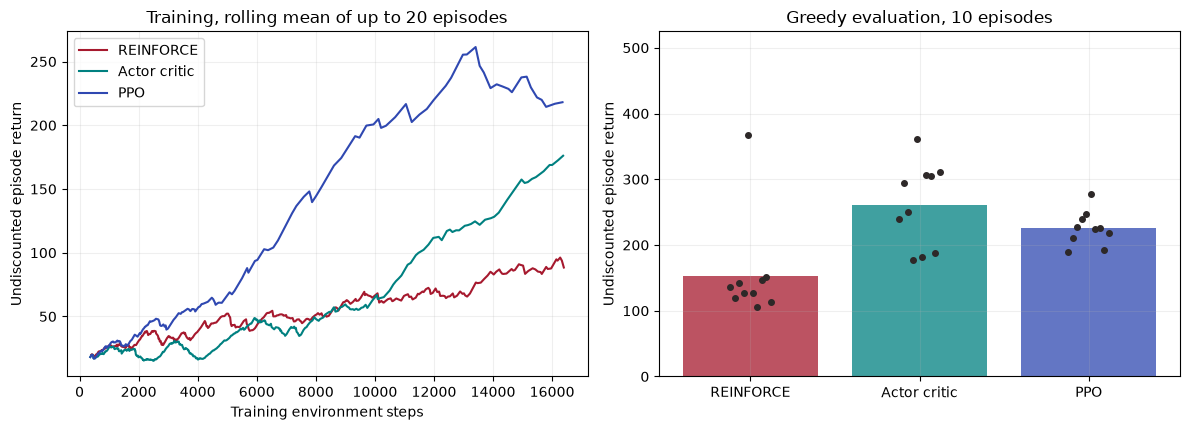

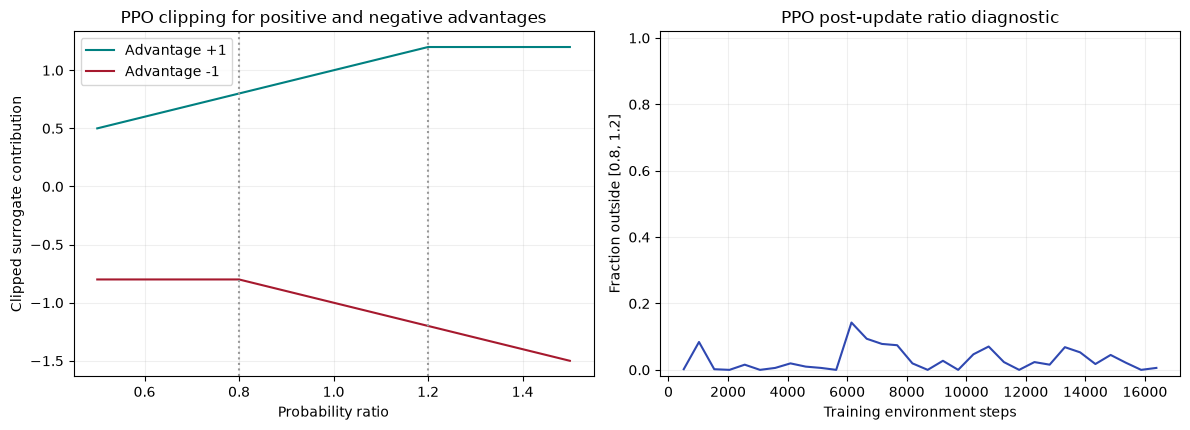

In [28]:
# Provided results table and figures.
COLORS = {"REINFORCE": "#A6192E", "Actor critic": "#008080", "PPO": "#2F48B1"}
COMPARISON_TABLE = []
LEARNING_FIGURE = None
CLIPPING_FIGURE = None

if set(EXPERIMENTS) == set(ALGORITHMS):
    print(f"{'Algorithm':<14} {'Steps':>7} {'Updates':>8} {'Episodes':>9} {'Eval mean':>10} {'Eval SD':>9} {'Seconds':>9}")
    for name in ALGORITHMS:
        result = EXPERIMENTS[name]
        evaluation = result["evaluation_returns"]
        row = dict(algorithm=name, steps=result["steps"], updates=result["updates"],
                   episodes=len(result["episode_returns"]), eval_mean=float(np.mean(evaluation)),
                   eval_std=float(np.std(evaluation, ddof=0)), seconds=result["elapsed_seconds"])
        COMPARISON_TABLE.append(row)
        print(f"{name:<14} {row['steps']:7d} {row['updates']:8d} {row['episodes']:9d} "
              f"{row['eval_mean']:10.1f} {row['eval_std']:9.1f} {row['seconds']:9.1f}")
        print("  Evaluation returns:", evaluation.tolist())

    LEARNING_FIGURE, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for name in ALGORITHMS:
        result = EXPERIMENTS[name]
        returns = np.asarray(result["episode_returns"], dtype=float)
        steps = np.asarray(result["episode_end_steps"])
        window = min(20, len(returns))
        average = np.convolve(returns, np.ones(window) / window, mode="valid")
        axes[0].plot(steps[window-1:], average, color=COLORS[name], label=name)
    axes[0].set(xlabel="Training environment steps", ylabel="Undiscounted episode return",
                title="Training, rolling mean of up to 20 episodes")
    axes[0].legend()
    x = np.arange(len(ALGORITHMS))
    axes[1].bar(x, [row["eval_mean"] for row in COMPARISON_TABLE],
                color=[COLORS[name] for name in ALGORITHMS], alpha=0.75)
    for i, name in enumerate(ALGORITHMS):
        values = EXPERIMENTS[name]["evaluation_returns"]
        axes[1].scatter(np.full(len(values), i) + np.linspace(-0.12, 0.12, len(values)),
                        values, color="#2D2828", s=16, zorder=3)
    axes[1].set_xticks(x, ALGORITHMS)
    axes[1].set(ylabel="Undiscounted episode return", title="Greedy evaluation, 10 episodes", ylim=(0, 525))
    for ax in axes:
        ax.grid(alpha=0.2)
    LEARNING_FIGURE.tight_layout()
    plt.show()

    CLIPPING_FIGURE, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    ratios = torch.linspace(0.5, 1.5, 201)
    old = torch.full_like(ratios, math.log(0.5))
    for advantage, color in [(1., "#008080"), (-1., "#A6192E")]:
        surrogate = []
        for ratio in ratios:
            loss, _ = ppo_policy_loss((old[:1] + ratio.log()), old[:1],
                                       torch.tensor([advantage]), 0.2)
            surrogate.append(-float(loss.detach()))
        axes[0].plot(ratios.numpy(), surrogate, color=color, label=f"Advantage {advantage:+.0f}")
    axes[0].axvline(0.8, color="0.6", linestyle=":")
    axes[0].axvline(1.2, color="0.6", linestyle=":")
    axes[0].set(xlabel="Probability ratio", ylabel="Clipped surrogate contribution",
                title="PPO clipping for positive and negative advantages")
    axes[0].legend()
    ppo = EXPERIMENTS["PPO"]
    axes[1].plot(ppo["diagnostic_steps"], ppo["clip_fractions"], color="#2F48B1")
    axes[1].set(xlabel="Training environment steps", ylabel="Fraction outside [0.8, 1.2]",
                title="PPO post-update ratio diagnostic", ylim=(-0.02, 1.02))
    for ax in axes:
        ax.grid(alpha=0.2)
    CLIPPING_FIGURE.tight_layout()
    plt.show()
else:
    print("Results skipped until all three experiments are available.")

In [29]:
# CHECK G, do not edit. Reward thresholds are deliberately absent.
def validate_run(name):
    assert name in EXPERIMENTS, f"Run {name}."
    result = EXPERIMENTS[name]
    assert result["seed"] == SEED and result["steps"] >= REQUIRED_STEPS
    if name != "REINFORCE":
        assert result["steps"] == REQUIRED_STEPS
    else:
        assert result["steps"] < REQUIRED_STEPS + 4 * MAX_EPISODE_STEPS
    assert result["updates"] > 0 and result["updates"] == len(result["losses"])
    assert len(result["gradient_norms"]) == result["updates"]
    for key in ("losses", "gradient_norms", "episode_returns", "episode_end_steps"):
        assert len(result[key]) > 0 and np.all(np.isfinite(result[key]))
    assert len(result["episode_returns"]) == len(result["episode_end_steps"])
    assert np.all(np.diff(result["episode_end_steps"]) > 0)
    assert result["episode_end_steps"][-1] <= result["steps"]
    assert all(1 <= value <= MAX_EPISODE_STEPS for value in result["episode_returns"])
    assert all(torch.isfinite(p).all() for p in result["model"].parameters())
    if name == "PPO":
        assert len(result["clip_fractions"]) == REQUIRED_STEPS // 512
        assert len(result["approx_kls"]) == len(result["diagnostic_steps"]) == len(result["clip_fractions"])
        assert np.all(np.isfinite(result["approx_kls"]))
        assert all(0 <= value <= 1 for value in result["clip_fractions"])

@check("G1")
def test_G1():
    validate_run("REINFORCE")

@check("G2")
def test_G2():
    validate_run("Actor critic")

@check("G3")
def test_G3():
    validate_run("PPO")

@check("G4")
def test_G4():
    assert len(COMPARISON_TABLE) == 3
    assert [row["algorithm"] for row in COMPARISON_TABLE] == list(ALGORITHMS)
    for name, row in zip(ALGORITHMS, COMPARISON_TABLE):
        values = np.asarray(EXPERIMENTS[name]["evaluation_returns"])
        assert values.shape == (EVAL_EPISODES,)
        assert np.all(np.isfinite(values)) and np.all((1 <= values) & (values <= 500))
        assert math.isclose(row["eval_mean"], float(values.mean()), abs_tol=1e-8)
        assert math.isclose(row["eval_std"], float(values.std(ddof=0)), abs_tol=1e-8)
        assert np.isfinite(row["seconds"]) and row["seconds"] > 0

@check("G5")
def test_G5():
    assert isinstance(LEARNING_FIGURE, Figure) and isinstance(CLIPPING_FIGURE, Figure)
    assert len(LEARNING_FIGURE.axes) == len(CLIPPING_FIGURE.axes) == 2
    assert len(LEARNING_FIGURE.axes[0].lines) == 3
    for line in LEARNING_FIGURE.axes[0].lines:
        assert len(line.get_xdata()) > 0 and np.all(np.isfinite(line.get_ydata()))
    assert len(CLIPPING_FIGURE.axes[1].lines[0].get_ydata()) == REQUIRED_STEPS // 512

run_checks("G")

PASS G1, 2 points, REINFORCE training outputs
PASS G2, 2 points, actor critic training outputs
PASS G3, 2 points, PPO training outputs
PASS G4, 2 points, evaluation outputs and comparison table
PASS G5, 2 points, learning and PPO clipping figures


/home/wyatt/Documents/GitHub/AE696/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## Final grading summary

This cell reruns every check against the current functions and outputs, then prints the fixed 100-point rubric. Unregistered checks count as failures. The instructor can rerun the same checks after **Restart Kernel and Run All**. The score is a transparent grading aid; changing checks, substituting fabricated training data, or hardcoding fixture answers does not satisfy the assignment.

An unfinished starter notebook prints failed checks and skips training. That is expected. Your submitted notebook must contain completed implementations, actual training outputs, both figures, and identification.

In [30]:
# FINAL CHECK, do not edit.
run_checks(verbose=False)
earned = 0
for key, (points, description) in RUBRIC.items():
    passed = LAB4_CHECKS[key]["passed"]
    awarded = points if passed else 0
    earned += awarded
    print(f"{'PASS' if passed else 'FAIL':4s} {key:2s} {awarded:2d}/{points:2d}  {description}")
print(f"\nPUBLIC CHECK SCORE: {earned}/100")
identified = bool(STUDENT_NAME.strip() and RED_ID.strip())
print("Identification entered:", identified)
if earned == 100 and identified:
    print("All public checks passed. Save the notebook with its outputs before submission.")
else:
    print("Complete missing items, restart the kernel, run all cells, and save.")

PASS A1  4/ 4  selected action log probabilities
PASS A2  3/ 3  entropy and vector shapes
PASS A3  3/ 3  policy gradient through logits
PASS B1  8/ 8  discounted rewards to go
PASS B2  6/ 6  REINFORCE sign and episode average
PASS B3  6/ 6  REINFORCE gradients and detached weights
PASS C1  8/ 8  continuing, terminal, and truncated TD targets
PASS C2  4/ 4  detached TD targets
PASS C3  4/ 4  actor loss and critic isolation
PASS C4  4/ 4  critic loss and fixed target
PASS D1  7/ 7  GAE recursion and value targets
PASS D2  4/ 4  GAE resets and rollout boundary
PASS D3  4/ 4  GAE lambda zero and detached results
PASS E1  6/ 6  PPO ratios and fixed old policy
PASS E2  8/ 8  PPO clipping for both advantage signs
PASS E3  6/ 6  PPO gradients and detached advantages
PASS F1  5/ 5  zero gradients, backpropagate, clip, and step
PASS G1  2/ 2  REINFORCE training outputs
PASS G2  2/ 2  actor critic training outputs
PASS G3  2/ 2  PPO training outputs
PASS G4  2/ 2  evaluation outputs and compariso

## References and optional exploration

The supplied implementation is intentionally compact: a single environment, separate actor and critic networks, an unclipped value loss, and fixed PPO update epochs. It does not implement TRPO or continuous-action policies.

Reference documentation:

1. [Gymnasium CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/)
2. [Gymnasium termination and truncation](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/)
3. [PyTorch categorical distributions](https://docs.pytorch.org/docs/stable/distributions.html#categorical)
4. [OpenAI Spinning Up, PPO](https://spinningup.openai.com/en/latest/algorithms/ppo.html)
5. [Schulman et al., Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347)
6. [Schulman et al., Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438)

After saving the required outputs, you may use separate cells to try a larger training budget, three seeds, or a different PPO clip parameter. These extensions carry no points and should not overwrite the required results.